## Превышение индикатора экономической капитализации престижа вернакулярного района Патриарших прудов над Китай-городом на основе данных о недвижимости

Уточнения:
- При подготовке датасета использовались открытые данные ЦИАН
- Районы Патриарших прудов и Китай-города, не существующие юридически, были взяты по выделенным районам на Яндекс.Картах
- Датасет offers_clean_final дополнялся дважды: половина объектов была добавлена в июле, половина в октябре
- В датасете учитано изменение курса доллара за 4 месяца, соответственно все июльские цены пересчитаны на октябрь
- Датасет был собран самостоятельно, также самостоятельно были отобраны предикторы 
- При нормализации табличных данных был использован генеративный Искуственный Интеллект для оптимизации работы

Цель: 
- Составить часть материала для анализа для курсовой работы 2 курса "Концентрация объектов розничной торговли высоких ценовых категорий на территориях с различной морфологией застройки в г.Москва". Доказать предположение о значимости статуса места в ценообразовании недвижимости на примере районов Патриарших прудов и Китай-города

## Установка и импорт библиотек для работы, загрузка датасета

In [28]:
!pip install statsmodels # Устанавливаем статсмоделс
import pandas as pd # Подгружаем небоходимые библиотеки
import numpy as np
import matplotlib.pyplot as plt

In [29]:
import statsmodels.formula.api as smf # Подключаем библиотеку статсмоделс для построения OLS-регрессии

In [43]:
dataset_ols = pd.read_excel('Offers_clean_final.xlsx') # Считываем файл с помощью Пандас
dataset_ols.head() # Отображаем шапку файла

,row_num,cian_listing_id,rooms,nearest_metro,metro_time_min,address,total_area_m2,ln_total_area_m2,living_area_m2,floor,...,renovation_type,renovation_index,bathrooms_count,ceiling_height_m,ceiling_height_category,ceiling_height_index,patriki_dummy,listing_url,Unnamed: 25,data_collection_date
0,1,327564269,2.0,Тверская,9,"Москва, Большой Козихинский переулок, 17С1",54.3,3.994524,NaN,3,...,Евроремонт,2.0,1.0,3.60,высокие,2.0,1,https://www.cian.ru/sale/flat/327564269,NaN,2026-07-14
1,2,330583850,5.0,Баррикадная,13,"Москва, Гранатный переулок, 6",332.2,5.805737,305.0,2,...,Дизайнерский,3.0,4.0,3.40,средние,1.0,1,https://www.cian.ru/sale/flat/330583850,NaN,2026-07-14
2,3,330950257,4.0,Баррикадная,13,"Москва, Гранатный переулок, 6",163.5,5.096813,NaN,2,...,Без ремонта,0.0,3.0,3.70,высокие,2.0,1,https://www.cian.ru/sale/flat/330950257,NaN,2026-07-14
3,4,329526731,3.0,Тверская,10,"Москва, Малая Бронная улица, 15Б",137.1,4.920711,75.0,2,...,Дизайнерский,3.0,3.0,3.25,средние,1.0,1,https://www.cian.ru/sale/flat/329526731,NaN,2026-07-14
4,5,320034913,5.0,Тверская,7,"Москва, Тверской бульвар, 16С5",160.0,5.075174,139.9,8,...,Дизайнерский,3.0,6.0,3.00,средние,1.0,1,https://www.cian.ru/sale/flat/320034913,NaN,2026-07-14


## Построение графического материала для оценки обстановки на рынке двух районов

- Графики построены на основе предварительно расставленных фиктивных переменных для дальнейшего построения модели
- Цена ('Price_rub') и площадь ('total_area_m2') были прологарифмированы в связи с нормами работы со статистикой в недвижимости

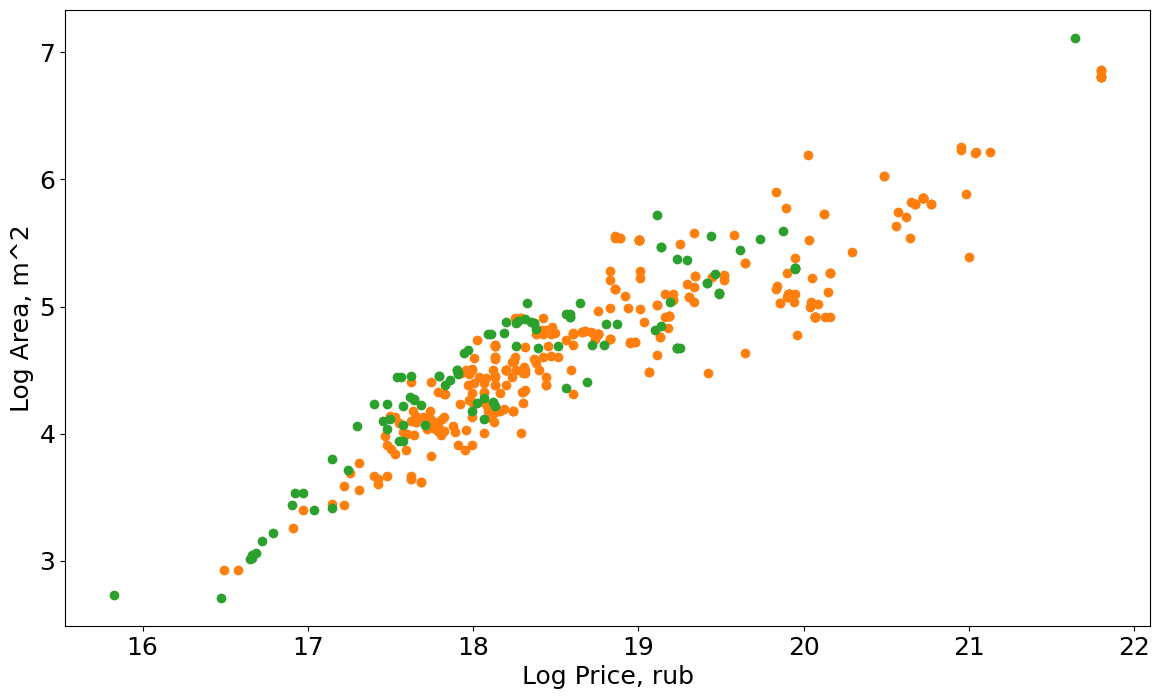

In [49]:
# Строим Скаттерплот для квартир на Патриках и Китай-городе
patriki_cloud = dataset_ols[dataset_ols['patriki_dummy']==1] # Квартиры на патриках
ct_cloud = dataset_ols[dataset_ols['patriki_dummy']==0] # Квартиры на КГ

plt.figure(figsize=(14, 8)) # Создаем фигуру для скаттерплота

plt.scatter(np.log(patriki_cloud['price_rub']), np.log(patriki_cloud['total_area_m2']), c='C1') # Обычная стоимость не отражает логику рынка, потому принято логарифмировать, что мы и сделали
plt.scatter(np.log(ct_cloud['price_rub']), np.log(ct_cloud['total_area_m2']), c='C2') # Здесь абсолютно та же практика с логарфмированием

plt.xlabel('Log Price, rub', fontsize = 18)
plt.ylabel('Log Area, m^2', fontsize = 18)
plt.gca().tick_params(labelsize=18) 

## Подготовка данных для построения модели OLS

In [51]:
# Перейдем к построению непосредственной OLS
dataset_ols['ln_price'] = np.log(dataset_ols['price_rub']) # Построим внутри файла столбец логарифма стоимости, так как предварительно в датасете забыл
dataset_ols['patriki_dummy'].value_counts() # Выводим количество объектов на Патриках (320) и на Китай-Городе (102)

patriki_dummy
1    320
0    102
Name: count, dtype: int64

## Построение базовой OLS-регрессионной модели

Почему базовой? Здесь попытаемся просто посмотреть на то, как район ('Patriki_dummy') и логарифм площади ('ln_total_area_m2') объясняют стоимость недвижимости

In [59]:
model = smf.ols( # Встроенная в smf функция для построения OLS
    formula = 'ln_price ~ patriki_dummy + ln_total_area_m2', # Формула модели просит на вход просто названия столбцов в датасете, а также что и чем мы хотим объяснить
    data = dataset_ols).fit() # По синтаксису предусматривает стандартную ошибку при построении модели
print(model.summary()) # Функция для вывода подробного статистического отчета

                            OLS Regression Results                            
Dep. Variable:               ln_price   R-squared:                       0.845
Model:                            OLS   Adj. R-squared:                  0.844
Method:                 Least Squares   F-statistic:                     1138.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          4.44e-170
Time:                        01:19:24   Log-Likelihood:                -240.57
No. Observations:                 422   AIC:                             487.1
Df Residuals:                     419   BIC:                             499.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           12.0462      0.141  

## Интерпретация результатов

Удалось получить подробный статистический отчет по OLS. Объяснение основных получившихся показателей: 

- R-squared - коэффициент детерминации. Его значение равно `0,845` или же `84,5%`. (или же `84,4%` при скорректированном)
   - Это говорит о том, что модели удалось объяснить 84% изменчивости цены. Для недвижимости это считается очень хорошим показателем.
- Prob (F-statistic) - p-value или же вероятность ошибки для модели. Значение `4.44e-170`.
   - Данный показатель ничтожно мало при норме 0,05 и меньше для обоснованности модели. В нашем случае это означает, что модель статистически значима, то есть переменные выбраны не случайно
- No. Observations - говорит о количестве объектов в выборке. `422`
   - В нашем случае это замечательно, так как все объекты вошли в модель
- Df Model - степени свободы модели. `2`
   - По сути это количество переменных. В моем случае их две: `'Patriki_dummy'` и `'ln_total_area_m2'`
- Df Residuals - степени свободы остатков. `419`
   - Рассчитывается, как разница между количеством объектов в модели и количеством оцененных параметров. Чем выше это значение - тем лучше. Пока у нас параметров заметно меньше, чем будет позже.
 
Основные результаты модели: 

- мы получили во второй части отчета три строки и шесть столбцов. (intercept - свободный член...)
   - Первое, на что мы обращаем внимание - P>|t|. В нашем случае этот показатель во всех строках близок к нулю (но не равен ему!), соответственно вероятность того, что параметры `'patriki_dummy'` и `'ln_total_area_m2'` попали в модель случайно, стремится к нулю, то есть оба фактора сто процентов значимы для объяснения цены.
- Убедившись в значении влияния, следует перейти к коэффициентам coef, которые помогут нам дать ответ, насколько это влияние сильно.
   - Здесь важно обратить внимание на знак. В нашем случае он положителен у всех строк, соответственно при росте фактора цена растет.
   - Описывая коэффициент при `patriki_dummy`, можно сделать вывод, что цена на недвижимость на Патриках выше на 23,57%, однако если переводить по точной формуле - это значение будет `26,6%` `(e^'наша доля' - 1)`, что является подтверждением гипотезы о том, что цены там выше
   - Коэффициент при `ln_total_area_m2` равен `1,3716%` (НЕ 137,16%), так как в данном случае и зависимая переменная, и предиктор представлены логарифмами. Как интеерпретировать это значение? При увеличении площади на 1% цена квартиры увеличивается на 1,3716%.

Проверив прочие параметры со второго блока отчета, мы можем убедиться в том, что значимость локации безоговорочна, а площадь - вовсе главный "предсказатель" в нашей модели.

Проверяя результаты по третьей части блока отчета, можно с уверенностью сказать, что модель работает и отображает суть. Значения p-value здесь также меньше 0,05. 

## Построение OLS с робастной стандартной ошибкой HC1 (гетероскедастически-робастные стандартные ошибки)


In [61]:
model = smf.ols(
    formula = 'ln_price ~ patriki_dummy + ln_total_area_m2',
    data = dataset_ols).fit(cov_type='HC1') # Непосредственно переходим на HC1 
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               ln_price   R-squared:                       0.845
Model:                            OLS   Adj. R-squared:                  0.844
Method:                 Least Squares   F-statistic:                     1497.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          1.47e-191
Time:                        01:39:07   Log-Likelihood:                -240.57
No. Observations:                 422   AIC:                             487.1
Df Residuals:                     419   BIC:                             499.3
Df Model:                           2                                         
Covariance Type:                  HC1                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           12.0462      0.118  

## Интепретация результатов 

В данной модели было решено добавить гетероскедастически-робастные стандартные ошибки HC1. Это обусловлено тем, что в данных о ценах недвижимости дисперсия необъясненных ценовых различий по идее может варьироваться между объектами. 
Значения с предыдущей моделью практически не изменились. Она также валидна.

## Создание полной модели со всеми возможными предикторами (в соответствии со стандартом)

- Используется стандартная ошибка HC1
- Добавляются предикторы `'rooms'` , `'bathrooms_count'`, `'floor'`, `'total_floors'`, `'renovation_index'`, `'parking_index'`, `'metro_time_min'`

In [64]:
model = smf.ols( # Добавляем в модель
    formula = 'ln_price ~ patriki_dummy + ln_total_area_m2 + rooms + bathrooms_count + floor + total_floors + renovation_index + parking_index + metro_time_min',
    data = dataset_ols).fit(cov_type='HC1') 
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               ln_price   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     554.6
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          5.39e-208
Time:                        00:01:29   Log-Likelihood:                -115.68
No. Observations:                 378   AIC:                             251.4
Df Residuals:                     368   BIC:                             290.7
Df Model:                           9                                         
Covariance Type:                  HC1                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           11.5430      0.193  

## Модель провалилась 

Из ключевых проблем: 

- Проблема жесткой мультиколлинеарности (по причине сильной связи `'rooms'` и `'ln_total_area_m2'`), на что указывает число обусловленности `Cond. No.`, которое взлетело с 33,8 до 158 при норме до 30.
- Несколько предикторов потеряли свою значимость, включая `'patriki_dummy'`, так как значение p-value стало выше 0,05.
- Встречаются аномальные проблемы: чем дальше от метро - тем цены на недвижимость выше, а не наоборот. Это скорее не проблема, а интересная специфика рынка элитной недвижимости, где в глубине улиц в тишине цены выше.

## Борьба с мультиколлинеарностью и очищение модели от избыточного шума

- Убираем значения с превышающим норму p-value
- Боремся с мультиколлинеарностью

In [68]:
model = smf.ols(
    formula = 'ln_price ~ patriki_dummy + ln_total_area_m2 + bathrooms_count + parking_index', # Очищаем модель
    data = dataset_ols).fit(cov_type='HC1')
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               ln_price   R-squared:                       0.868
Model:                            OLS   Adj. R-squared:                  0.867
Method:                 Least Squares   F-statistic:                     1005.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):          1.38e-203
Time:                        12:00:45   Log-Likelihood:                -182.51
No. Observations:                 394   AIC:                             375.0
Df Residuals:                     389   BIC:                             394.9
Df Model:                           4                                         
Covariance Type:                  HC1                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           12.7729      0.153  

## Результаты эконометрического моделирования стоимости недвижимости

Избавившись от шума и минимизировав мультиколлинеарность до допустимых значений, удалось получить следующие результаты:
- R-squared - коэффициент детерминации. Его значение равно `0,868` или же `86,8%`. (при скорректированном `86,7`)
- Prob (F-statistic) - p-value или же вероятнось ошибки для модели меньше `0,05`, соответственно модель статистически значима
- No. Observations - `394`. Модель обучена на 394 объектах датасета.

Интерпретация значимых факторов:
- `'ln_total_area_m2'`. p-value меньше 0,05. При увеличении площади на 1%, ее площадь в среднем увеличивается на 1,14%. Наблюдается ускоренный рост цены с увеличением размеров объекта, как эффект недвижимости элитного сегмента.
- `'parking_index'`. p-value практически равно 0. Наличие качественной парковочной инфраструктуры увеличивает стоимость объекта недвижимости приблизительно на `26,74%` или же на `30,6%` при более точном переводе (e^0,2674 - 1)
- `'bathrooms_count'`. Каждый дополнительный санузел заложенный в планировку квартиру увеличивает ее стоимость в среднем на 7,95% (8,27%)

И главное... 
- `'patriki_dummy'`. Факт нахождения квартиры в районе Патриарших прудов обеспечивает чистую преимальную наценку к стоимости в размере `13,76%` или же `14,75` при `e^0,1376 - 1`

## Вывод

В ходе исследования была построена и оптимизирована множественная линейная регрессия (метод OLS) для оценки факторов, определяющих рыночную стоимость квартир элитного сегмента. Оптимизация проводилась методом обратного исключения, что позволило очистить модель от статистического шума, устранить логические аномалии и минимизировать мультиколлинеарность. Качество финальной модели подтверждается скорректированным коэффициентом детерминации Adj. R-squared = `0.867`: модель на `86.7%` объясняет ценообразование в выборке из `394` объектов.

В ходе моделирования выяснилось, что главным экономическим драйвером безусловно является площадь, где более крупные объекты имеют прогрессирующую наценку, что указывает на специфику рынка недвижимости элитного сегмента. В свою очередь также одним из сильнейших драйверов, только уже инфраструктурных, является развитый паркинг в условиях дефицита парковочных мест в центре Москвы. 
Для ценообразования, как и предполагалось, важным оказалось и место: нахождение квартиры в районе Патриарших прудов дает статусную наценку около `15%` по сравнению с аналогичными по площади и прочими характеристиками жильем в районе Китай-города. 
Также несколько удивительным и интересным оказалось то, что каждая лишняя ванная комната добавляет к цене порядка `8%`, что указывает на важность наличия мастер-спален (то есть спален сразу с санузлом и тп) в ценообразовании для данного сегмента. 

Также были выделены параметры, которые влияют на цену удивительно незначительно или вовсе не оказывают влияния, а лишь служат шумом. Безусловно, пришлось избавиться от параметра количества комнат, так как он практически повторяет общую площадь квартиры, также оказалось, что качество отделки квартиры оказалось совершенно незначимым, что, вероятно, также можно соотнести с особенностями рынка: в преимальном сегменте ремонт является субъективным и изменчивым фактором; покупатели часто делают перепланировку и ремонт под себя, потому рынок не закладывает ремонт в долгосрочную стоимость цен. 
Особенно примечательным оказалось, что близость к метро не то что не увеличивает стоимость недвижимости или не влияет на нее, а вовсе лишь ее рушит: для недвижимости центра Москвы близость к метро перестает быть преимуществом в силу большого потока людей и шума, потому самые дорогие дома скрыты в тихих переулках, а их жители практически всегда перемещаются на машинах. 

Данное исследование помогло не только определить премию за недвижимость в районе Патриарших прудов по сравнению с Китай-городом, но и выйти на выводы о поведении потребителя, представляющего праздный класс, что безусловно поможет при написании курсового проекта.